# Models (multiple linear regression and random forest), model evaluation and interpretation

**This Jupyter notebook does the following:**

- Reads the data from the SQLite database `Data/topic1_apartments.db`
- Creates the model variables (dummy variables for the renovation groups, renovated parts, building period, language region)
- **Model 1 (main research question and sub-question 1):** multiple linear regression of the net rent per m² on the renovation group and control variables
- **Model 2 (sub-question 2):** multiple linear regression with the renovated parts instead of the renovation groups
- **Model 3:** random forest regression with the same variables as model 1, feature importance
- Evaluates the models with R² and RMSE on a test sample (80 % train / 20 % test) and with 5-fold cross-validation
- Robustness checks: robust standard errors (HC3) and gross rent per m² as target variable
- Interprets the results

The structure follows `Week_13/linear_regression.ipynb` and `Week_13/regression_trees_random_forest.ipynb`.

## Libraries and settings

In [1]:
# Libraries
import os
import sqlite3
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Show current working directory
print(os.getcwd())

C:\Users\DELL\Documents\applied_research_methods\Project_Topic1


## Importing the data from the database

In [2]:
conn = sqlite3.connect('./Data/topic1_apartments.db')
df_orig = pd.read_sql_query('''SELECT a.*, m.bfs_name, m.canton, m.language_region, m.population_density,
                                      m.foreigners_pct, m.mean_taxable_income
                               FROM apartments AS a
                               JOIN municipalities AS m ON a.bfs_number = m.bfs_number''', con=conn)
conn.close()
print('Dimension:', df_orig.shape)

Dimension: (726, 39)


## Model variables

| Variable | Meaning |
|---|---|
| `rent_net_per_m2` | **target variable**: net rent per m² (CHF) |
| `energy_reno`, `general_reno` | 1 = energy / general renovation (reference: not renovated) |
| `area`, `rooms` | living area (m²), number of rooms |
| `built_...` | building period (reference: built 1961–1980); building age is very skewed (some buildings are several hundred years old), so periods are used instead of the age in years |
| `log_population_density` | logarithm of the population density of the municipality |
| `taxable_income_1000` | mean taxable income of the municipality (1'000 CHF) |
| `foreigners_pct` | share of foreigners in the municipality (%) |
| `french`, `italian` | language region (reference: German-speaking) |
| `furnished`, `temporary` | furnished / temporary listing |
| `immoscout` | listing from ImmoScout24 (reference: flatfox) |
| `reno_complete`, `reno_kitchen`, `reno_bathroom`, `reno_floors` | renovated parts (model 2) |
| `energy_measure` | at least one energy measure: windows, heating, insulation, roof, solar or Minergie (model 2) |
| `reno_unspecified` | renovated, but the description does not say what (model 2) |

In [3]:
df = df_orig.copy()

# Renovation groups (reference: not renovated)
df['energy_reno'] = (df['renovation_group'] == 'energy renovation').astype(int)
df['general_reno'] = (df['renovation_group'] == 'general renovation').astype(int)

# Building period (reference: 1961-1980)
df['built_before_1919'] = (df['year_built'] < 1919).astype(int)
df['built_1919_1945'] = df['year_built'].between(1919, 1945).astype(int)
df['built_1946_1960'] = df['year_built'].between(1946, 1960).astype(int)
df['built_1981_1989'] = df['year_built'].between(1981, 1989).astype(int)

# Location
df['log_population_density'] = np.log(df['population_density'])
df['taxable_income_1000'] = df['mean_taxable_income'] / 1000
df['french'] = (df['language_region'] == 'French').astype(int)
df['italian'] = (df['language_region'] == 'Italian').astype(int)

# Listing
df['immoscout'] = df['source'].isin(['immoscout24', 'both']).astype(int)

# Renovated parts (model 2)
energy_cols = ['energy_windows', 'energy_heating', 'energy_insulation', 'energy_roof', 'energy_solar', 'energy_minergie']
df['energy_measure'] = (df[energy_cols].sum(axis=1) > 0).astype(int)
df['reno_unspecified'] = ((df['renovation_group'] != 'not renovated') & (df['renovated_parts'] == 'not specified')).astype(int)

controls = ['area', 'rooms', 'built_before_1919', 'built_1919_1945', 'built_1946_1960', 'built_1981_1989',
            'log_population_density', 'taxable_income_1000', 'foreigners_pct', 'french', 'italian', 'furnished', 'temporary', 'immoscout']
x_model1 = ['energy_reno', 'general_reno'] + controls
x_model2 = ['energy_measure', 'reno_complete', 'reno_kitchen', 'reno_bathroom', 'reno_floors', 'reno_unspecified'] + controls

# Sample: apartments with net rent per m² and all explanatory variables
data = df.dropna(subset=['rent_net_per_m2', 'year_built', 'taxable_income_1000'] + controls).reset_index(drop=True)
print('Apartments in the model sample:', len(data))
print(data['renovation_group'].value_counts())

Apartments in the model sample: 542
renovation_group
general renovation    348
not renovated         164
energy renovation      30
Name: count, dtype: int64


## Create train and test samples

80 % of the apartments are used to fit the models (train), 20 % to evaluate the predictions (test). The split is **stratified** by renovation group, so that the small energy group is in both samples in the same share.

In [4]:
y = data['rent_net_per_m2']
train_idx, test_idx = train_test_split(data.index, test_size=0.20, random_state=42,
                                       stratify=data['renovation_group'])
print('Train:', len(train_idx), '| Test:', len(test_idx))
print('Energy-renovated apartments in train / test:',
      data.loc[train_idx, 'energy_reno'].sum(), '/', data.loc[test_idx, 'energy_reno'].sum())

Train: 433 | Test: 109
Energy-renovated apartments in train / test: 24 / 6


## Model 1: multiple linear regression (main research question and sub-question 1)

### Fit on the train sample and evaluate on the test sample

In [5]:
# Add constant to the model
X1_train = sm.add_constant(data.loc[train_idx, x_model1])
X1_test = sm.add_constant(data.loc[test_idx, x_model1])

# Create and fit the multiple regression model
olsres1 = sm.OLS(y[train_idx], X1_train).fit()

# Print full model output
print(olsres1.summary())

                            OLS Regression Results                            
Dep. Variable:        rent_net_per_m2   R-squared:                       0.439
Model:                            OLS   Adj. R-squared:                  0.417
Method:                 Least Squares   F-statistic:                     20.34
Date:                Thu, 26 Nov 2026   Prob (F-statistic):           7.77e-43
Time:                        17:13:27   Log-Likelihood:                -1343.2
No. Observations:                 433   AIC:                             2720.
Df Residuals:                     416   BIC:                             2790.
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      6

In [6]:
def evaluate(name, y_train, pred_train, y_test, pred_test):
    return {'model': name,
            'R² train': r2_score(y_train, pred_train),
            'R² test': r2_score(y_test, pred_test),
            'RMSE train': np.sqrt(mean_squared_error(y_train, pred_train)),
            'RMSE test': np.sqrt(mean_squared_error(y_test, pred_test))}

results = [evaluate('Model 1: linear regression (renovation groups)',
                    y[train_idx], olsres1.predict(X1_train), y[test_idx], olsres1.predict(X1_test))]
pd.DataFrame(results).round(3)

,model,R² train,R² test,RMSE train,RMSE test
0,Model 1: linear regression (renovation groups),0.439,0.438,5.382,6.113


### Residuals of model 1

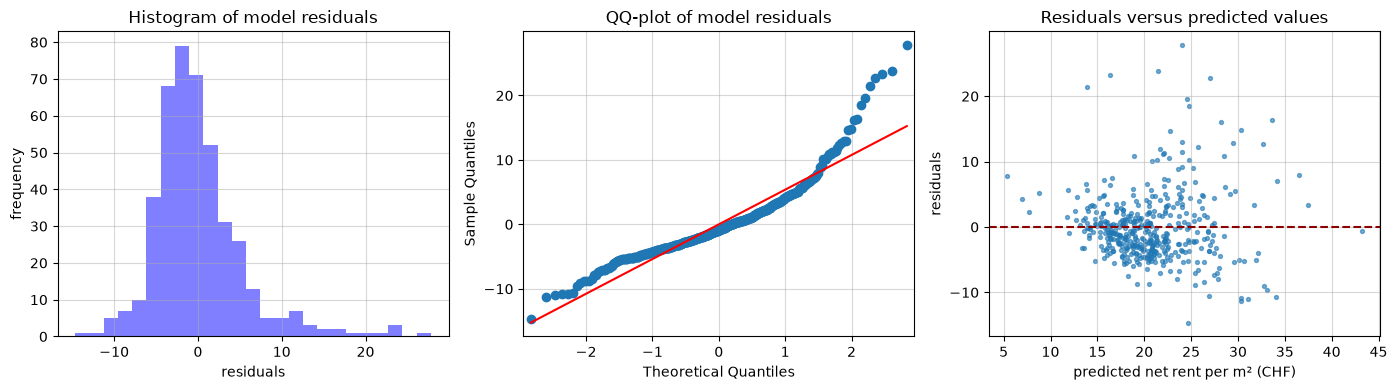

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(olsres1.resid, bins=25, color='blue', alpha=0.5)
axes[0].set_xlabel('residuals')
axes[0].set_ylabel('frequency')
axes[0].set_title('Histogram of model residuals')

sm.qqplot(olsres1.resid, line='s', ax=axes[1])
axes[1].set_title('QQ-plot of model residuals')

axes[2].scatter(olsres1.fittedvalues, olsres1.resid, s=8, alpha=0.6)
axes[2].axhline(0, color='darkred', linestyle='dashed')
axes[2].set_xlabel('predicted net rent per m² (CHF)')
axes[2].set_ylabel('residuals')
axes[2].set_title('Residuals versus predicted values')

for ax in axes:
    ax.grid(alpha=0.5)
plt.tight_layout()
plt.show()

### Observed versus predicted net rent per m² (test sample)

In [8]:
pred_test1 = olsres1.predict(X1_test)
for i in range(0, 10):
    print(f'Observed: {y[test_idx].iloc[i]:.2f}, Predicted: {pred_test1.iloc[i]:.2f}')

Observed: 25.84, Predicted: 21.04
Observed: 17.18, Predicted: 20.33
Observed: 24.11, Predicted: 22.90
Observed: 36.79, Predicted: 25.78
Observed: 24.52, Predicted: 25.28
Observed: 13.23, Predicted: 14.82
Observed: 14.71, Predicted: 16.98
Observed: 17.68, Predicted: 17.25
Observed: 38.10, Predicted: 58.48
Observed: 19.86, Predicted: 19.43


### Model 1 on all apartments (for the interpretation of the coefficients)

The train/test split is used to evaluate the **predictions**. To estimate the **rent premium** as precisely as possible, model 1 is also fitted on all apartments (more energy-renovated apartments → smaller standard errors).

- **Main research question:** coefficient of `energy_reno` (difference to *not renovated*)
- **Sub-question 1:** test whether `energy_reno` = `general_reno` (t-test of the difference of the two coefficients)

In [9]:
X1_all = sm.add_constant(data[x_model1])
olsres1_all = sm.OLS(y, X1_all).fit()

def coef_table(res, variables):
    ci = res.conf_int()
    return pd.DataFrame({'coefficient': res.params[variables],
                         'std. error': res.bse[variables],
                         'p-value': res.pvalues[variables],
                         'CI 2.5 %': ci.loc[variables, 0],
                         'CI 97.5 %': ci.loc[variables, 1]}).round(4)

print(f'n = {int(olsres1_all.nobs)}, R² = {olsres1_all.rsquared:.3f}, adj. R² = {olsres1_all.rsquared_adj:.3f}\n')
coef_table(olsres1_all, x_model1)

n = 542, R² = 0.460, adj. R² = 0.443



,coefficient,std. error,p-value,CI 2.5 %,CI 97.5 %
energy_reno,4.6126,1.1467,0.0001,2.3600,6.8652
general_reno,0.9798,0.5524,0.0767,-0.1053,2.0649
area,-0.0737,0.0135,0.0000,-0.1002,-0.0472
rooms,-0.2387,0.3552,0.5018,-0.9365,0.4591
built_before_1919,2.6093,0.7909,0.0010,1.0556,4.1629
built_1919_1945,1.4993,0.8291,0.0711,-0.1294,3.1280
built_1946_1960,0.7779,0.7343,0.2899,-0.6647,2.2205
built_1981_1989,-0.1143,0.6736,0.8653,-1.4375,1.2089
log_population_density,0.9055,0.2797,0.0013,0.3561,1.4550
taxable_income_1000,0.1833,0.0167,0.0000,0.1504,0.2161


In [10]:
# Sub-question 1: H0: coefficient(energy_reno) = coefficient(general_reno)
t1 = olsres1_all.t_test('energy_reno - general_reno = 0')
diff = olsres1_all.params['energy_reno'] - olsres1_all.params['general_reno']
print(f'Difference energy - general renovation: {diff:.2f} CHF per m²')
print(f't-value: {float(np.squeeze(t1.tvalue)):.3f}, p-value: {float(np.squeeze(t1.pvalue)):.4f}')

Difference energy - general renovation: 3.63 CHF per m²
t-value: 3.359, p-value: 0.0008


### Robustness check 1: robust standard errors (HC3)

The residual plots show that the variance of the residuals is not constant (heteroscedasticity). Robust standard errors (HC3) do not need this assumption. The coefficients stay the same; only the p-values change.

In [11]:
olsres1_hc3 = sm.OLS(y, X1_all).fit(cov_type='HC3')
pd.DataFrame({'coefficient': olsres1_all.params[['energy_reno', 'general_reno']],
              'p-value (OLS)': olsres1_all.pvalues[['energy_reno', 'general_reno']],
              'p-value (HC3)': olsres1_hc3.pvalues[['energy_reno', 'general_reno']]}).round(4)

,coefficient,p-value (OLS),p-value (HC3)
energy_reno,4.6126,0.0001,0.0001
general_reno,0.9798,0.0767,0.0525


### Robustness check 2: gross rent per m² as target variable

The net rent is missing for about a quarter of the listings (also in the energy group). The gross rent (including Nebenkosten) is available for almost all apartments.

In [12]:
data_g = df.dropna(subset=['rent_per_m2', 'year_built', 'taxable_income_1000'] + controls).reset_index(drop=True)
olsres_g = sm.OLS(data_g['rent_per_m2'], sm.add_constant(data_g[x_model1])).fit()
print(f"n = {int(olsres_g.nobs)} (energy-renovated: {data_g['energy_reno'].sum()}), R² = {olsres_g.rsquared:.3f}\n")
coef_table(olsres_g, ['energy_reno', 'general_reno'])

n = 685 (energy-renovated: 43), R² = 0.438



,coefficient,std. error,p-value,CI 2.5 %,CI 97.5 %
energy_reno,2.5222,1.0572,0.0173,0.4464,4.5979
general_reno,0.7749,0.5562,0.1640,-0.3172,1.8669


### Robustness check 3: without doubtful energy-renovated apartments

Some apartments in the energy group are doubtful:

- **no energy measure** was found in the description (e.g. only "complete renovation"); a keyword such as *Fassade* put them in the energy group
- the **renovation year is before 1990** (e.g. 1925), so the energy renovation is very old or the year is wrong

These apartments are removed and model 1 is fitted again (net rent and gross rent). If the premium stays similar, the result does not depend on these doubtful cases.

In [13]:
doubtful = ((df['renovation_group'] == 'energy renovation') &
            ((df['energy_measure'] == 0) | (df['year_renovated'] < 1990)))
print('Doubtful energy-renovated apartments:', doubtful.sum())
display(df.loc[doubtful, ['locality', 'address', 'year_renovated', 'renovated_parts', 'rent_net_per_m2', 'rent_per_m2']])

Doubtful energy-renovated apartments: 6


,locality,address,year_renovated,renovated_parts,rent_net_per_m2,rent_per_m2
162,Bern,"Rathausgasse 24, 3011 Bern",1989.0,"complete, bathroom, floors, windows, heating",34.17,36.33
205,Weier im Emmental,"Käsereistrasse 4, 3462 Weier im Emmental",2009.0,complete,14.50,16.50
248,Aarau,"Feerstrasse 15, 5000 Aarau",2014.0,complete,NaN,24.00
283,Seuzach,"Mörsburgstrasse 8, 8472 Seuzach",2026.0,not specified,25.38,27.69
551,Wil,9500 Wil,1925.0,"complete, heating",NaN,21.00
711,Naters,3904 Naters,2024.0,complete,23.71,26.57


In [14]:
rows = []
for target in ['rent_net_per_m2', 'rent_per_m2']:
    for name, d in [('all apartments', df), ('without doubtful cases', df[~doubtful])]:
        d = d.dropna(subset=[target, 'year_built', 'taxable_income_1000'] + controls)
        res = sm.OLS(d[target], sm.add_constant(d[x_model1])).fit()
        ci = res.conf_int().loc['energy_reno']
        rows.append({'target variable': target, 'sample': name, 'n': int(res.nobs),
                     'n energy': int(d['energy_reno'].sum()),
                     'energy_reno': res.params['energy_reno'], 'p-value': res.pvalues['energy_reno'],
                     'CI 2.5 %': ci[0], 'CI 97.5 %': ci[1],
                     'general_reno': res.params['general_reno']})
pd.DataFrame(rows).round(4)

,target variable,sample,n,n energy,energy_reno,p-value,CI 2.5 %,CI 97.5 %,general_reno
0,rent_net_per_m2,all apartments,542,30,4.6126,0.0001,2.3600,6.8652,0.9798
1,rent_net_per_m2,without doubtful cases,538,26,4.3394,0.0004,1.9661,6.7126,0.9809
2,rent_per_m2,all apartments,685,43,2.5222,0.0173,0.4464,4.5979,0.7749
3,rent_per_m2,without doubtful cases,679,37,2.4819,0.0265,0.2910,4.6727,0.7781


## Model 2: multiple linear regression with the renovated parts (sub-question 2)

Instead of the three groups, the model contains one dummy variable per renovated part. Each coefficient is the difference in net rent per m² **when the other parts and the control variables are held constant**. Reference: apartments without any renovation information.

In [15]:
X2_train = sm.add_constant(data.loc[train_idx, x_model2])
X2_test = sm.add_constant(data.loc[test_idx, x_model2])
olsres2 = sm.OLS(y[train_idx], X2_train).fit()

results.append(evaluate('Model 2: linear regression (renovated parts)',
                        y[train_idx], olsres2.predict(X2_train), y[test_idx], olsres2.predict(X2_test)))

# Coefficients on all apartments
olsres2_all = sm.OLS(y, sm.add_constant(data[x_model2])).fit()
parts = ['energy_measure', 'reno_complete', 'reno_kitchen', 'reno_bathroom', 'reno_floors', 'reno_unspecified']
print('Number of apartments with the part:')
print(data[parts].sum(), '\n')
print(f'n = {int(olsres2_all.nobs)}, R² = {olsres2_all.rsquared:.3f}, adj. R² = {olsres2_all.rsquared_adj:.3f}\n')
coef_table(olsres2_all, parts)

Number of apartments with the part:
energy_measure       41
reno_complete       109
reno_kitchen         58
reno_bathroom        49
reno_floors          31
reno_unspecified    224
dtype: int64 

n = 542, R² = 0.466, adj. R² = 0.445



,coefficient,std. error,p-value,CI 2.5 %,CI 97.5 %
energy_measure,2.6193,0.9675,0.0070,0.7185,4.5200
reno_complete,2.3387,0.7073,0.0010,0.9492,3.7282
reno_kitchen,-1.4300,0.9827,0.1462,-3.3605,0.5006
reno_bathroom,0.5859,1.0975,0.5936,-1.5701,2.7420
reno_floors,-1.5994,1.2347,0.1958,-4.0251,0.8263
reno_unspecified,0.1231,0.5663,0.8280,-0.9895,1.2356


### Coefficients of the renovated parts with 95 % confidence intervals

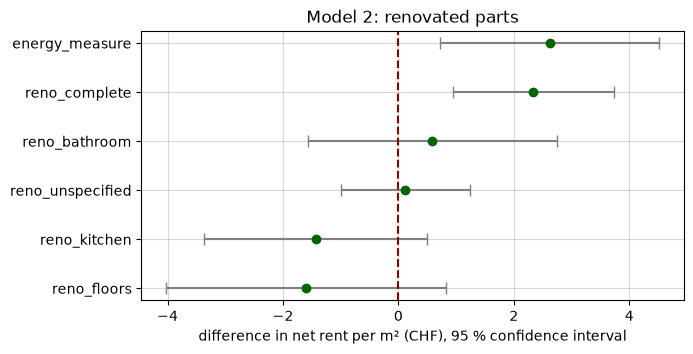

In [16]:
ct = coef_table(olsres2_all, parts).sort_values('coefficient')
plt.figure(figsize=(7, 3.5))
plt.errorbar(ct['coefficient'], ct.index, xerr=[ct['coefficient'] - ct['CI 2.5 %'], ct['CI 97.5 %'] - ct['coefficient']],
             fmt='o', color='darkgreen', ecolor='grey', capsize=4)
plt.axvline(0, color='darkred', linestyle='dashed')
plt.xlabel('difference in net rent per m² (CHF), 95 % confidence interval')
plt.title('Model 2: renovated parts')
plt.grid(alpha=0.5)
plt.show()

## Model 3: random forest regression

Same explanatory variables as model 1. A random forest can find non-linear relationships and interactions (e.g. a renovation premium that is higher in cities), but it does not give coefficients or p-values. The **feature importance** shows how much each variable contributes to the predictions.

In [17]:
# Initialize random forest regressor
reg_rf = RandomForestRegressor(n_estimators=500,
                               max_depth=10,
                               min_samples_leaf=3,
                               random_state=5)

# Train random forest regressor
reg_rf.fit(data.loc[train_idx, x_model1], y[train_idx])

results.append(evaluate('Model 3: random forest',
                        y[train_idx], reg_rf.predict(data.loc[train_idx, x_model1]),
                        y[test_idx], reg_rf.predict(data.loc[test_idx, x_model1])))
pd.DataFrame(results).round(3)

,model,R² train,R² test,RMSE train,RMSE test
0,Model 1: linear regression (renovation groups),0.439,0.438,5.382,6.113
1,Model 2: linear regression (renovated parts),0.448,0.429,5.337,6.159
2,Model 3: random forest,0.823,0.714,3.025,4.363


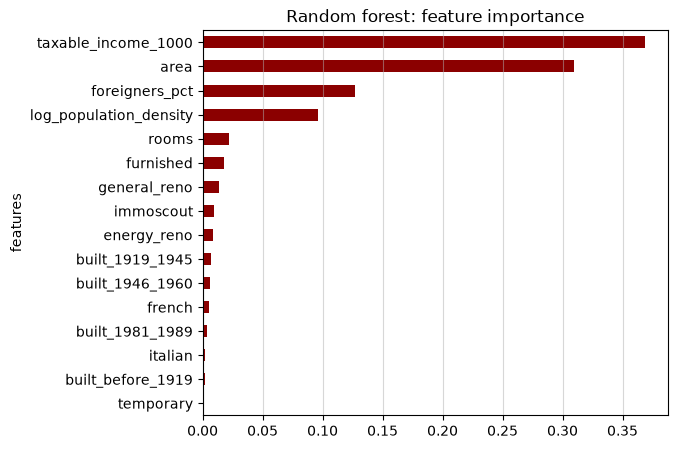

,features,importances
9,taxable_income_1000,0.369
2,area,0.310
10,foreigners_pct,0.127
8,log_population_density,0.096
3,rooms,0.022
13,furnished,0.018
1,general_reno,0.014
15,immoscout,0.010


In [18]:
# Derive feature importance from random forest
df_fi = pd.DataFrame({'features': x_model1, 'importances': reg_rf.feature_importances_})
df_fi.sort_values('importances', inplace=True)
df_fi.plot(kind='barh', y='importances', x='features', color='darkred', figsize=(6, 5), legend=False)
plt.title('Random forest: feature importance')
plt.grid(axis='x', alpha=0.5)
plt.show()

df_fi.sort_values('importances', ascending=False).round(3).head(8)

## Model comparison

### Measures of fit on the test sample

In [19]:
comparison = pd.DataFrame(results).round(3)
comparison

,model,R² train,R² test,RMSE train,RMSE test
0,Model 1: linear regression (renovation groups),0.439,0.438,5.382,6.113
1,Model 2: linear regression (renovated parts),0.448,0.429,5.337,6.159
2,Model 3: random forest,0.823,0.714,3.025,4.363


### 5-fold cross-validation

With only about 100 apartments in the test sample, R² and RMSE depend on which apartments happen to be in the test sample. 5-fold cross-validation splits the data five times and averages the results, which gives a more stable comparison.

In [20]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv = []
for name, cols, model in [('Model 1: linear regression', x_model1, LinearRegression()),
                          ('Model 2: linear regression (parts)', x_model2, LinearRegression()),
                          ('Model 3: random forest', x_model1,
                           RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_leaf=3, random_state=5))]:
    r2 = cross_val_score(model, data[cols], y, cv=kf, scoring='r2')
    rmse = -cross_val_score(model, data[cols], y, cv=kf, scoring='neg_root_mean_squared_error')
    cv.append({'model': name, 'R² (mean)': r2.mean(), 'R² (std)': r2.std(),
               'RMSE (mean)': rmse.mean(), 'RMSE (std)': rmse.std()})
pd.DataFrame(cv).round(3)

,model,R² (mean),R² (std),RMSE (mean),RMSE (std)
0,Model 1: linear regression,0.375,0.100,5.835,0.753
1,Model 2: linear regression (parts),0.363,0.086,5.891,0.678
2,Model 3: random forest,0.580,0.075,4.778,0.655


### Observed versus predicted values (test sample)

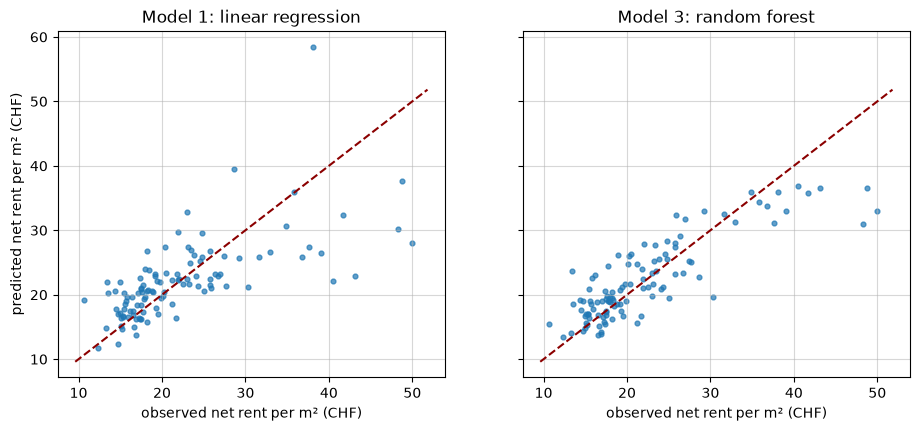

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (name, pred) in zip(axes, [('Model 1: linear regression', olsres1.predict(X1_test)),
                                   ('Model 3: random forest', reg_rf.predict(data.loc[test_idx, x_model1]))]):
    ax.scatter(y[test_idx], pred, s=12, alpha=0.7)
    lim = [y.min(), y.max()]
    ax.plot(lim, lim, color='darkred', linestyle='dashed')
    ax.set_xlabel('observed net rent per m² (CHF)')
    ax.set_title(name)
    ax.grid(alpha=0.5)
axes[0].set_ylabel('predicted net rent per m² (CHF)')
plt.show()

## Interpretation of the results

### Measures of fit

- **R²** is the share of the variation of the net rent per m² that the model explains. **RMSE** (root mean squared error) is the typical prediction error in CHF per m².
- **Model 1 (linear regression):** R² = 0.44 on the train sample and 0.44 on the test sample. The model explains about 44 % of the differences in net rent per m². Train and test values are almost the same, so the model is **not overfitted**. The typical prediction error on the test sample is about **6.1 CHF per m²** (for an 80 m² apartment about 490 CHF per month), compared with a mean net rent of about 21 CHF per m².
- **Model 2 (renovated parts):** almost the same fit as model 1 (R² test = 0.43). The renovated parts do not improve the predictions; the model is used to **explain** the rent premium, not to predict better.
- **Model 3 (random forest):** clearly the best predictions (R² test = 0.71, RMSE test = 4.4 CHF per m²; 5-fold cross-validation: R² = 0.58 versus 0.38 for the linear regression). The random forest can use non-linear relationships, e.g. the effect of the taxable income is not a straight line (very rich municipalities such as Feusisberg or Herrliberg). The R² on the train sample (0.82) is much higher than on the test sample, so the random forest overfits a little.
- The cross-validated R² values are lower than the values of the single test sample, which shows that the results depend on the split. The ranking of the models is the same.
- The residuals are **not normally distributed** (long tail to the right: a few very expensive apartments) and their variance increases with the predicted rent. The p-values were therefore also checked with robust standard errors (HC3); the conclusions do not change.

### Main research question: green premium

- In model 1 (all 542 apartments with net rent), energy-renovated apartments have a net rent that is **4.61 CHF per m² higher** than non-renovated apartments with the same living area, number of rooms, building period, municipality characteristics and language region (95 % confidence interval: 2.36 to 6.87 CHF; p < 0.001, also with HC3 standard errors).
- This is about **23 %** of the mean net rent of non-renovated apartments (20.24 CHF per m²), or about **370 CHF per month** for an 80 m² apartment.
- **H0 (main) is rejected:** energy-renovated older apartments have a significantly higher net rent per m².
- **Robustness:** with the gross rent per m² as target (685 apartments, 43 energy-renovated), the premium is smaller, **+2.52 CHF per m²** (p = 0.017), but still significant. A possible explanation is that energy-renovated apartments have lower Nebenkosten (lower heating costs), so the difference in gross rent is smaller than in net rent. This is not tested here.
- **Robustness without doubtful cases:** 6 energy-renovated apartments without an energy measure in the description or with a renovation year before 1990 were removed. The premium stays almost the same: **+4.34 CHF per m²** in net rent (p = 0.0004, 26 energy-renovated) and +2.48 CHF per m² in gross rent (p = 0.027). The result does not depend on these cases.

### Sub-question 1: energy renovation versus general renovation

- A general renovation is associated with only **+0.98 CHF per m²** (p = 0.077, not significant at the 5 % level).
- The difference between the two coefficients is **3.63 CHF per m²** (t-test of the difference: p < 0.001).
- **H0 (sub-question 1) is rejected:** the premium of an energy renovation is significantly higher than the premium of a general renovation.

### Sub-question 2: which renovated parts?

- **Energy measures** (windows, heating, insulation, roof, solar or Minergie): **+2.62 CHF per m²** (p = 0.007), **even when the renovated interior parts are held constant**.
- **Complete renovation:** +2.34 CHF per m² (p = 0.001).
- **Kitchen, bathroom, floors:** no significant effect (p > 0.1). Their effect is probably already contained in the "complete renovation" variable, and the groups are small.
- **Renovated, but not specified:** no difference to non-renovated apartments (+0.12, p = 0.83). Many of these renovations may be old or small.
- **H0 (sub-question 2) is rejected:** the energy premium is not only a "new kitchen premium".

### Control variables

- **Location is the most important driver** of the net rent per m²: +0.18 CHF per m² per 1'000 CHF higher mean taxable income of the municipality, higher rents in densely populated municipalities and in municipalities with a higher share of foreigners (cities). The random forest confirms this: taxable income and living area have the highest feature importance.
- **Larger apartments** have a lower rent per m² (−0.07 CHF per m² per additional m²).
- **Furnished apartments** are much more expensive (+9.8 CHF per m²).
- Buildings built **before 1919** have a higher rent per m² than buildings from 1961–1980 (+2.6 CHF; old-town apartments with charm).
- The platform (ImmoScout24 or flatfox) makes no significant difference.

### Limitations of the results

- Only **30 energy-renovated apartments** have a net rent; the estimate of the premium is therefore uncertain (wide confidence interval: 2.4 to 6.9 CHF per m²).
- The renovation groups and parts come from **keywords in the listing text**; some apartments are assigned to the wrong group.
- Listing rents are **asking rents**, not contract rents.
- The models show an **association, not a causal effect**: e.g. owners who renovate energetically may also have a higher interior standard that is not visible in the data.
- In the random forest, the renovation variables have a very low feature importance, because location and living area explain much more of the rent differences. The green premium is clearly visible in the linear regression, but it is small compared with the differences between locations.

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [22]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
NT
Windows | 10
Datetime: 2026-11-26 17:13:31
Python Version: 3.11.8
-----------------------------------
